In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/kerala_water_quality_preprocessed.csv")

df.head()

,_id,SlNo,Station,Agency,State_LGD_Code,State,District_LGD_Code,District,Tehsil,River,...,Tributary,Subtributary,SubSubtributary,Local_River,Latitude,Longitude,Data_Acquisition_Time,Biochemical_Oxygen_Demand_(mg/L),Fecal_Coliform_(MPN/100mL),Total_Coliform_(MPN/100mL)
0,1,1,ACHANKOVIL AT CHENNITHULA,CPCB,32,Kerala,554,Alappuzha,MAVELIKARA,-,...,-,-,-,-,9.270844,76.535403,2021-01-01 08:30:00,1.8,110.0,NaN
1,2,2,ACHANKOVIL AT CHENNITHULA,CPCB,32,Kerala,554,Alappuzha,MAVELIKARA,-,...,-,-,-,-,9.270844,76.535403,2021-02-09 08:30:00,1.9,110.0,NaN
2,3,3,ACHANKOVIL AT CHENNITHULA,CPCB,32,Kerala,554,Alappuzha,MAVELIKARA,-,...,-,-,-,-,9.270844,76.535403,2021-03-12 08:30:00,1.8,110.0,NaN
3,4,4,ACHANKOVIL AT CHENNITHULA,CPCB,32,Kerala,554,Alappuzha,MAVELIKARA,-,...,-,-,-,-,9.270844,76.535403,2021-04-03 08:30:00,1.9,110.0,NaN
4,5,5,ACHANKOVIL AT CHENNITHULA,CPCB,32,Kerala,554,Alappuzha,MAVELIKARA,-,...,-,-,-,-,9.270844,76.535403,2021-05-06 08:30:00,1.8,100.0,NaN


In [3]:
df.shape

(1155, 21)

In [4]:
df.columns

Index(['_id', 'SlNo', 'Station', 'Agency', 'State_LGD_Code', 'State',
       'District_LGD_Code', 'District', 'Tehsil', 'River', 'Basin',
       'Tributary', 'Subtributary', 'SubSubtributary', 'Local_River',
       'Latitude', 'Longitude', 'Data_Acquisition_Time',
       'Biochemical_Oxygen_Demand_(mg/L)', 'Fecal_Coliform_(MPN/100mL)',
       'Total_Coliform_(MPN/100mL)'],
      dtype='str')

In [5]:
df.dtypes

_id                                   int64
SlNo                                  int64
Station                                 str
Agency                                  str
State_LGD_Code                        int64
State                                   str
District_LGD_Code                     int64
District                                str
Tehsil                                  str
River                                   str
Basin                                   str
Tributary                               str
Subtributary                            str
SubSubtributary                         str
Local_River                             str
Latitude                            float64
Longitude                           float64
Data_Acquisition_Time                   str
Biochemical_Oxygen_Demand_(mg/L)    float64
Fecal_Coliform_(MPN/100mL)          float64
Total_Coliform_(MPN/100mL)          float64
dtype: object

In [6]:
df["Data_Acquisition_Time"] = pd.to_datetime(
    df["Data_Acquisition_Time"],
    errors="coerce"
)

In [7]:
df["Data_Acquisition_Time"].dtype

dtype('<M8[us]')

In [8]:
df["Data_Acquisition_Time"].agg(["min", "max"])

min   2021-01-01 08:30:00
max   2021-12-28 08:30:00
Name: Data_Acquisition_Time, dtype: datetime64[us]

In [10]:
df["Month"] = df["Data_Acquisition_Time"].dt.month

monthly_bod = df.groupby("Month")[
    "Biochemical_Oxygen_Demand_(mg/L)"
].mean()

monthly_bod

Month
1     2.362963
2     2.203448
3     2.291667
4     2.355738
5     2.253448
6     2.228302
7     2.200000
8     2.090909
9     2.228302
10    2.010169
11    2.174074
12    2.089189
Name: Biochemical_Oxygen_Demand_(mg/L), dtype: float64

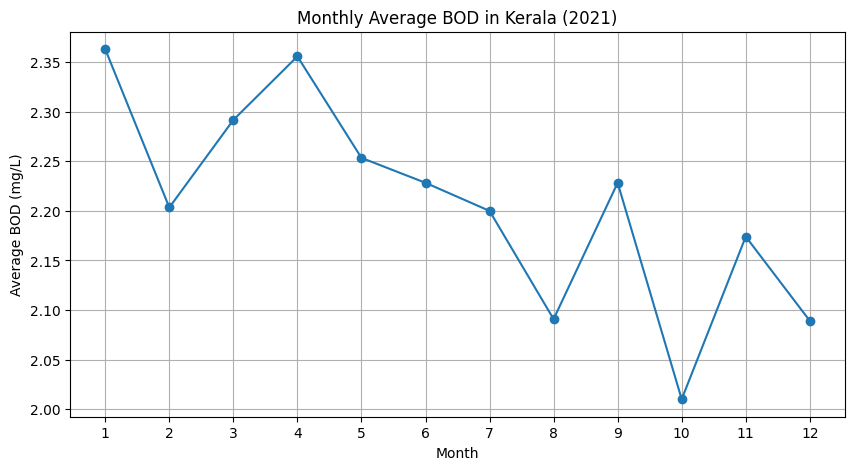

In [11]:
plt.figure(figsize=(10, 5))

monthly_bod.plot(marker="o")

plt.title("Monthly Average BOD in Kerala (2021)")
plt.xlabel("Month")
plt.ylabel("Average BOD (mg/L)")
plt.xticks(range(1, 13))
plt.grid(True)

plt.show()

### Monthly BOD Trend – Observations

- January recorded the highest monthly average BOD, approximately 2.36 mg/L.
- October recorded the lowest monthly average BOD, approximately 2.01 mg/L.
- BOD decreased overall from January to October, with fluctuations in between.
- April showed a temporary increase, while September and November also showed noticeable rises.
- December recorded an average BOD of approximately 2.09 mg/L.
- The monthly averages show variation in BOD measurements throughout 2021, but do not establish statistically significant seasonal changes.



In [12]:
monthly_fc = df.groupby("Month")[
    "Fecal_Coliform_(MPN/100mL)"
].mean()

monthly_fc

Month
1      656.283784
2      644.917808
3      390.235294
4      700.170000
5      815.017241
6     1056.279412
7      786.632353
8      649.869565
9      804.471429
10     835.908163
11    1120.463768
12    1500.191176
Name: Fecal_Coliform_(MPN/100mL), dtype: float64

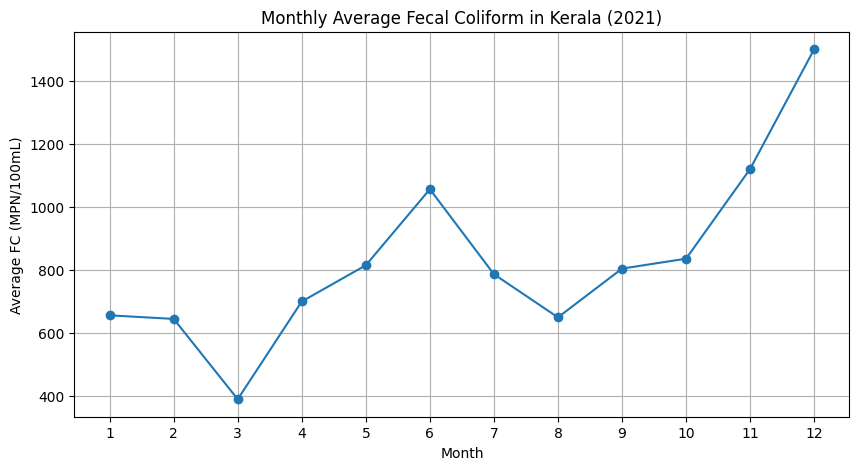

In [13]:
plt.figure(figsize=(10, 5))

monthly_fc.plot(marker="o")

plt.title("Monthly Average Fecal Coliform in Kerala (2021)")
plt.xlabel("Month")
plt.ylabel("Average FC (MPN/100mL)")
plt.xticks(range(1, 13))
plt.grid(True)

plt.show()

### Monthly Fecal Coliform Trend – Observations

- March recorded the lowest monthly average FC, approximately 390 MPN/100mL.
- December recorded the highest monthly average FC, approximately 1,500 MPN/100mL.
- FC averages increased substantially from March to June.
- July and August showed a decline in average FC.
- From September onward, FC averages generally increased, reaching their maximum in December.
- The monthly averages indicate considerable variation in fecal contamination measurements during 2021.
- Interpretation should account for missing observations and potentially extreme measurements.



In [14]:
monthly_tc = df.groupby("Month")[
    "Total_Coliform_(MPN/100mL)"
].mean()

monthly_tc

Month
1     2120.333333
2     4101.789474
3     5247.500000
4     4919.862745
5     1728.631579
6     2120.526316
7     5452.333333
8     1862.315789
9     5030.000000
10    1189.333333
11    3739.500000
12    4968.550000
Name: Total_Coliform_(MPN/100mL), dtype: float64

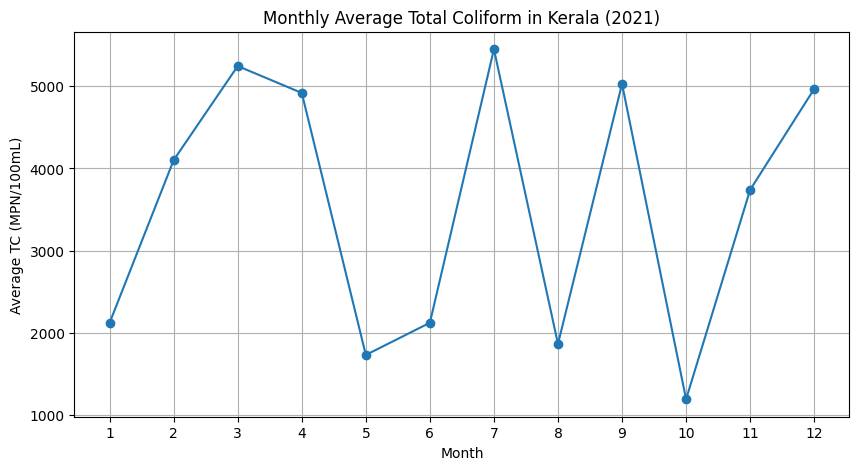

In [15]:
plt.figure(figsize=(10, 5))

monthly_tc.plot(marker="o")

plt.title("Monthly Average Total Coliform in Kerala (2021)")
plt.xlabel("Month")
plt.ylabel("Average TC (MPN/100mL)")
plt.xticks(range(1, 13))
plt.grid(True)

plt.show()

### Monthly Total Coliform Trend – Observations

- March recorded the highest monthly average TC, approximately 5,247 MPN/100mL.
- October recorded the lowest monthly average TC, approximately 1,189 MPN/100mL.
- TC averages increased considerably from January to March.
- May and October showed substantial decreases compared with adjacent months.
- July, September, and December recorded relatively high average TC values.
- TC measurements exhibited considerable month-to-month variability.
- The analysis is limited by the large proportion of missing TC measurements, and monthly averages may not represent all monitoring stations.



In [16]:
district_bod = df.groupby("District")[
    "Biochemical_Oxygen_Demand_(mg/L)"
].mean().sort_values(ascending=False)

district_bod

District
THIRUVANANTHAPURAM    3.691489
KOTTAYAM              2.420000
Alappuzha             2.234783
ERNAKULAM             2.208661
Kollam                2.141818
PATHANAMTHITTA        2.005000
PALAKKAD              1.901754
THRISSUR              1.768000
IDUKKI                1.766667
MALAPPURAM            1.726923
KOZHIKODE             1.719231
KASARAGOD             1.706522
KANNUR                1.564865
WAYANAD               1.340000
Name: Biochemical_Oxygen_Demand_(mg/L), dtype: float64

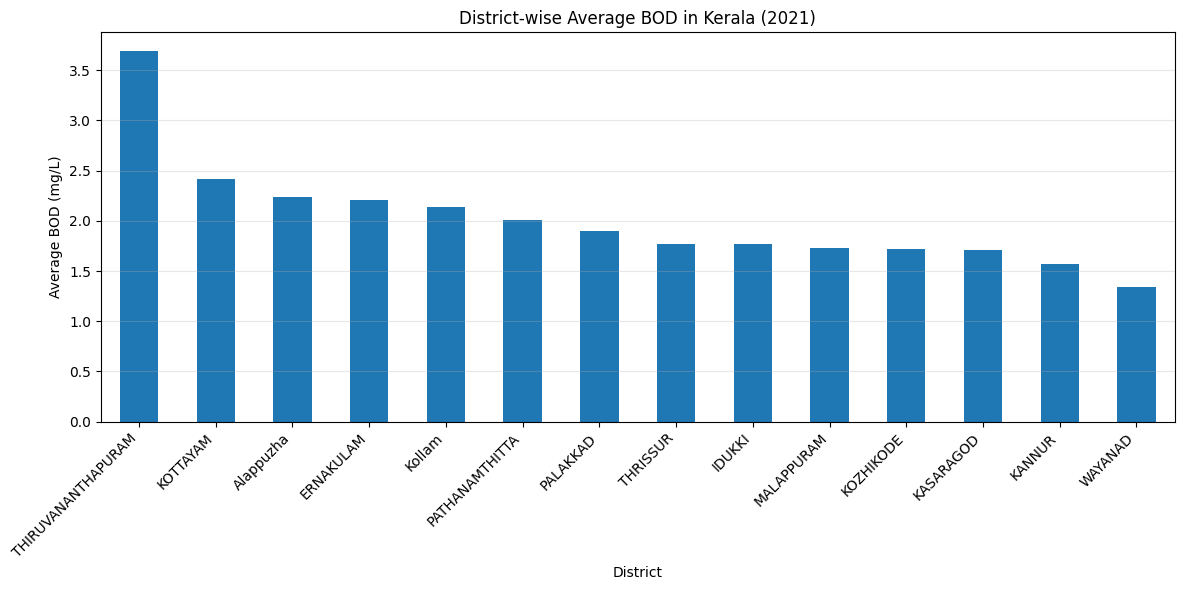

In [17]:
plt.figure(figsize=(12, 6))

district_bod.plot(kind="bar")

plt.title("District-wise Average BOD in Kerala (2021)")
plt.xlabel("District")
plt.ylabel("Average BOD (mg/L)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### District-wise BOD Analysis – Observations

- Thiruvananthapuram recorded the highest average BOD, approximately 3.69 mg/L.
- Kottayam recorded the second-highest average, approximately 2.42 mg/L.
- Alappuzha and Ernakulam showed average BOD values around 2.2 mg/L.
- Wayanad recorded the lowest average BOD, approximately 1.34 mg/L.
- The bar chart shows differences in average BOD measurements across districts.
- These differences may reflect actual water quality variation as well as differences in sampling coverage and available observations.



In [18]:
district_fc = df.groupby("District")[
    "Fecal_Coliform_(MPN/100mL)"
].mean().sort_values(ascending=False)

district_fc

District
KOZHIKODE             4442.311688
IDUKKI                2371.666667
ERNAKULAM             1105.183007
THIRUVANANTHAPURAM     893.421053
KOTTAYAM               497.307692
MALAPPURAM             487.533333
THRISSUR               413.109091
PALAKKAD               245.412698
PATHANAMTHITTA         238.046875
Alappuzha              118.859375
Kollam                  93.500000
KASARAGOD               85.294872
KANNUR                  61.175258
WAYANAD                 34.153846
Name: Fecal_Coliform_(MPN/100mL), dtype: float64

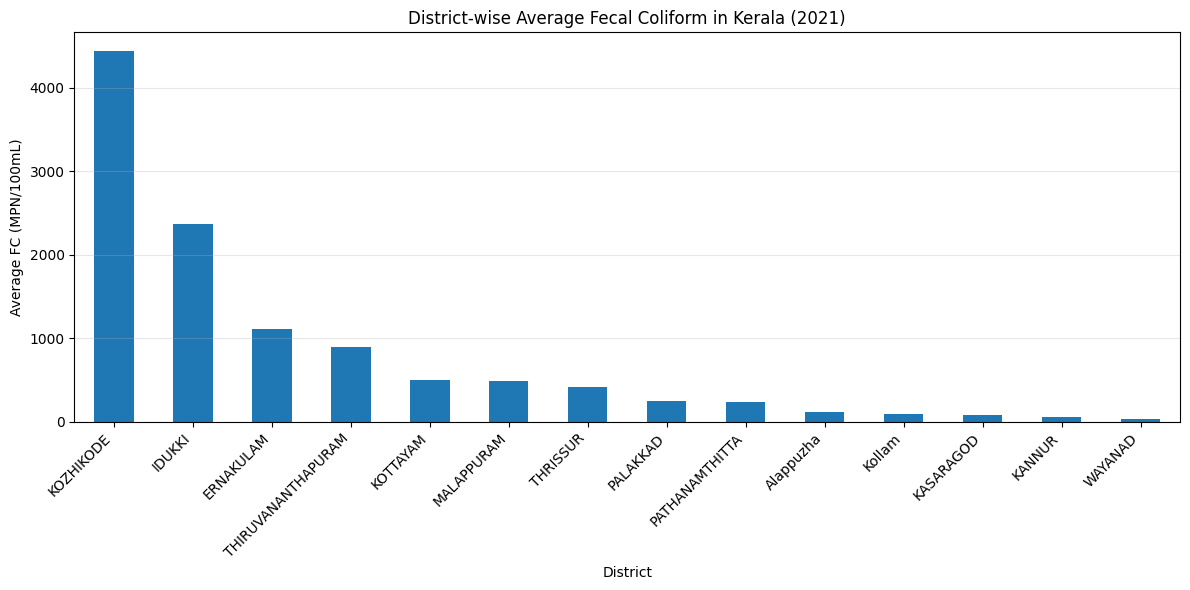

In [19]:
plt.figure(figsize=(12, 6))

district_fc.plot(kind="bar")

plt.title("District-wise Average Fecal Coliform in Kerala (2021)")
plt.xlabel("District")
plt.ylabel("Average FC (MPN/100mL)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### District-wise Fecal Coliform Analysis – Observations

- Kozhikode recorded the highest average FC, approximately 4,442 MPN/100mL.
- Idukki recorded the second-highest average, approximately 2,372 MPN/100mL.
- Ernakulam recorded approximately 1,105 MPN/100mL.
- Wayanad recorded the lowest average FC, approximately 34 MPN/100mL.
- The graph shows substantial differences in average FC measurements across districts.
- District comparisons should be interpreted cautiously because of missing measurements, extreme values, and uneven sampling coverage.



In [20]:
district_tc = df.groupby("District")[
    "Total_Coliform_(MPN/100mL)"
].mean().sort_values(ascending=False)

district_tc

District
ERNAKULAM             13124.344828
THIRUVANANTHAPURAM     2520.500000
PATHANAMTHITTA         2042.000000
THRISSUR               1812.857143
Alappuzha              1157.428571
KOZHIKODE              1065.533333
KOTTAYAM                948.333333
PALAKKAD                437.142857
Kollam                  347.727273
KANNUR                  256.615385
MALAPPURAM              111.000000
IDUKKI                  106.692308
WAYANAD                  37.285714
KASARAGOD                      NaN
Name: Total_Coliform_(MPN/100mL), dtype: float64

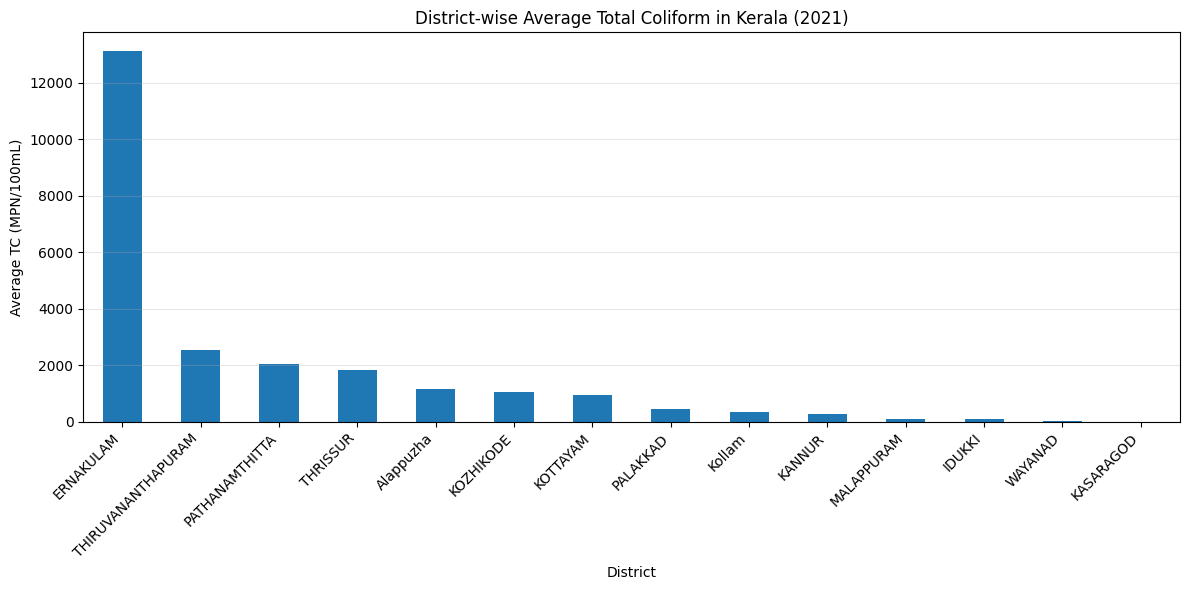

In [21]:
plt.figure(figsize=(12, 6))

district_tc.plot(kind="bar")

plt.title("District-wise Average Total Coliform in Kerala (2021)")
plt.xlabel("District")
plt.ylabel("Average TC (MPN/100mL)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### District-wise Total Coliform Analysis – Observations

- Ernakulam recorded the highest average TC, approximately 13,124 MPN/100mL.
- Thiruvananthapuram recorded approximately 2,520 MPN/100mL.
- Pathanamthitta recorded approximately 2,042 MPN/100mL.
- Thrissur recorded approximately 1,858 MPN/100mL.
- Wayanad recorded approximately 37 MPN/100mL.
- Kasaragod had no valid TC measurements, resulting in a missing average.
- The graph shows considerable variation in recorded TC averages across districts.
- TC comparisons are limited by substantial missing data and differences in sample availability.



In [22]:
station_bod = df.groupby("Station")[
    "Biochemical_Oxygen_Demand_(mg/L)"
].mean().sort_values(ascending=False)

station_bod.head(10)

Station
KARAMANA AT MOONNATTUMUKKU KERALA                           7.300000
POND AT (PADMANABHA) SREE PADMANABHA SWAMY TEMPLE (TVPM)    6.383333
ORUVATHILKOTTA LAKE KERALA                                  6.054545
KAYAMKULAM KERALA                                           3.491667
ASHTHAMUDI LAKE AT QUILON KERALA                            3.027273
R KADAMBAYAR AT BRAHMAPURAM                                 2.983333
IRUMPANAM KERALA                                            2.820000
UNTHITHODU AT ELOOR ERNAKULAM                               2.783333
VELLAYANI LAKE AT VANDITHADOM THIRUVANANTHAPURAM            2.708333
MANIMALA AT THONDRA KERALA                                  2.700000
Name: Biochemical_Oxygen_Demand_(mg/L), dtype: float64

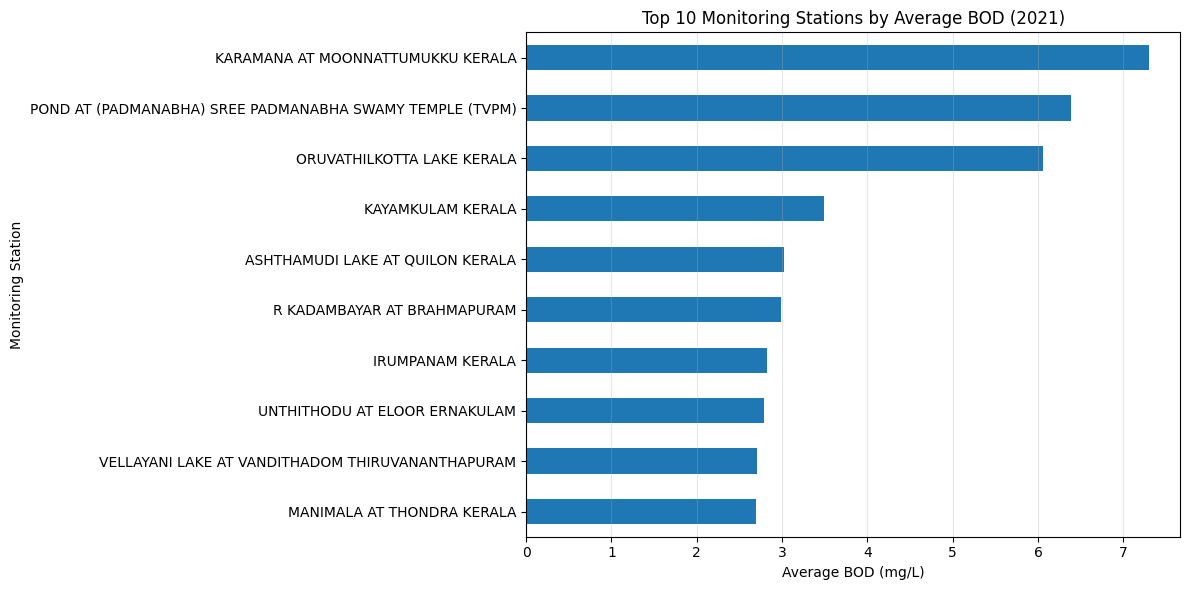

In [23]:
plt.figure(figsize=(12, 6))

station_bod.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Monitoring Stations by Average BOD (2021)")
plt.xlabel("Average BOD (mg/L)")
plt.ylabel("Monitoring Station")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### Station-wise BOD Analysis – Observations

- Karamana at Moonattumukku recorded the highest average BOD, approximately 7.30 mg/L.
- Pond at Padmanabha Sree Padmanabha Swamy Temple recorded approximately 6.38 mg/L.
- Oravathilkotta Lake recorded approximately 6.05 mg/L.
- Kayamkulam recorded approximately 3.49 mg/L.
- The remaining stations in the top 10 had average BOD values between approximately 2.7 and 3.3 mg/L.
- The station-level comparison reveals localized variation in recorded BOD measurements.
- These results are based on available observations and may be influenced by station sampling frequency.



In [24]:
station_fc = df.groupby("Station")[
    "Fecal_Coliform_(MPN/100mL)"
].mean().sort_values(ascending=False)

station_fc.head(10)

Station
R KALLAI AT KALLAI BRIDGE                   17925.000000
KARAMANA AT MOONNATTUMUKKU KERALA            4658.333333
VALAYAM KERALA                               3721.666667
IRUMPANAM KERALA                             2675.000000
PERIYAR AT SEWAGE DISCHARGE POINT KERALA     2371.666667
CHALIYAR AT CHUNGAPALLY                      2319.166667
CHALIYAR AT KOOLIMADU                        1929.166667
RIVER PERIYAR AT PATHALAM                    1895.000000
CHALIYAR AT NILAMBUR MALAPPURAM              1873.636364
R PERIYAR AT KALAMASSERY                     1685.000000
Name: Fecal_Coliform_(MPN/100mL), dtype: float64

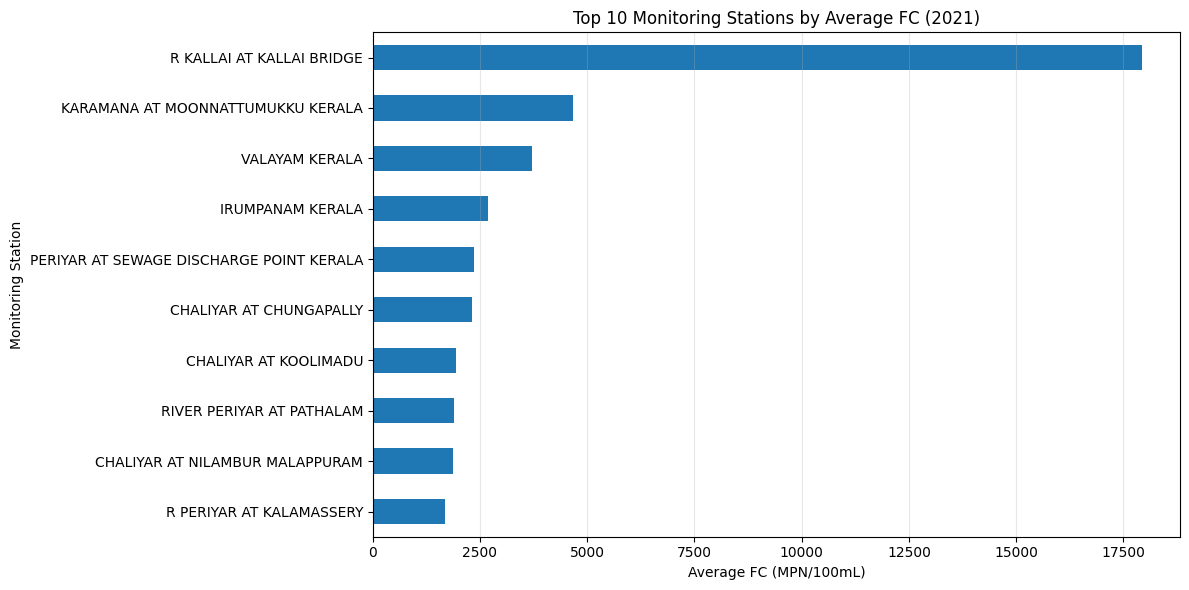

In [25]:
plt.figure(figsize=(12, 6))

station_fc.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Monitoring Stations by Average FC (2021)")
plt.xlabel("Average FC (MPN/100mL)")
plt.ylabel("Monitoring Station")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### Station-wise Fecal Coliform Analysis – Observations

- Kallai Bridge recorded the highest average FC, approximately 17,925 MPN/100mL.
- Karamana at Moonattumukku recorded approximately 4,658 MPN/100mL.
- Valayam recorded approximately 3,721 MPN/100mL.
- Irumpanam recorded approximately 2,675 MPN/100mL.
- Several monitoring stations along the Periyar River also appeared among the top 10.
- The station-level graph shows substantial variation in recorded fecal coliform measurements.
- The results should be interpreted cautiously because of missing measurements and possible differences in sampling frequency.



In [26]:
station_tc = df.groupby("Station")[
    "Total_Coliform_(MPN/100mL)"
].mean().sort_values(ascending=False)

station_tc.head(10)

Station
VEMBANAD LAKEKOCHI (OIL TANKER JETTY) KERALA                34375.000000
PALAKKATTUTHAZHA-MTHODU AT PERUMBAVOOR ERNAKULAM            17900.000000
UNTHITHODU AT ELOOR ERNAKULAM                                8516.666667
POND AT (PADMANABHA) SREE PADMANABHA SWAMY TEMPLE (TVPM)     4808.333333
ORUVATHILKOTTA LAKE KERALA                                   2450.000000
KANOLI CANAL AT ERANJIKKAL KAZHEKODE                         2092.500000
WELL AT ALWAYE KERALA                                        2042.000000
KODUNGALLOOR KERALA                                          1968.333333
RSVR AT BHOOTHATHANKETU                                      1881.166667
KAYAMKULAM KERALA                                            1727.500000
Name: Total_Coliform_(MPN/100mL), dtype: float64

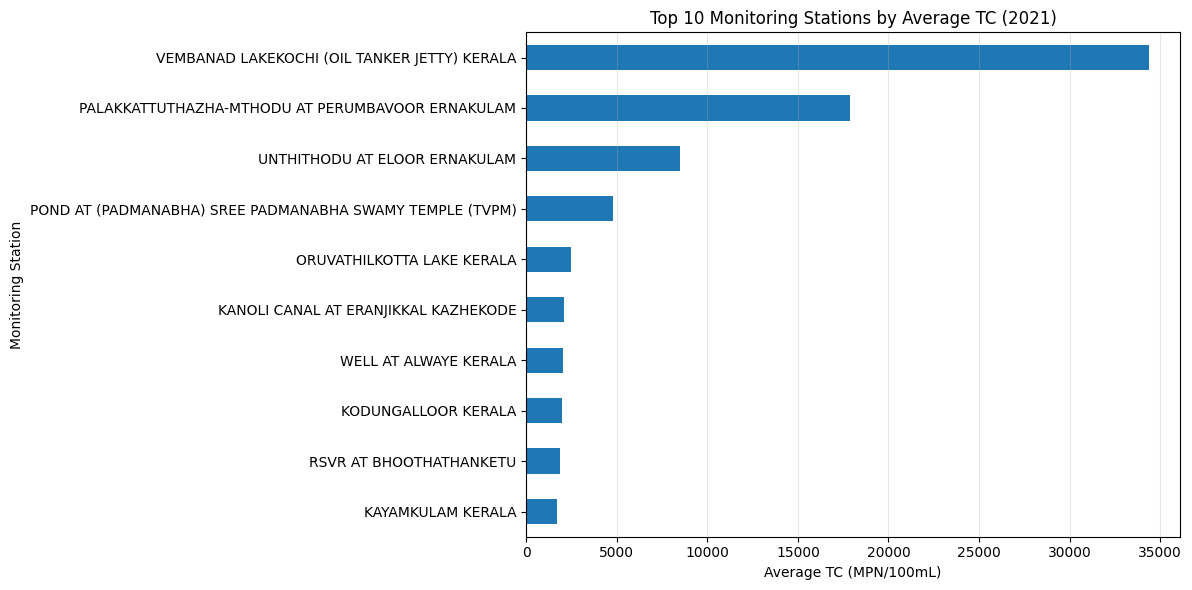

In [27]:
plt.figure(figsize=(12, 6))

station_tc.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Monitoring Stations by Average TC (2021)")
plt.xlabel("Average TC (MPN/100mL)")
plt.ylabel("Monitoring Station")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### Station-wise Total Coliform Analysis – Observations

- Vembanad Lake Kochi recorded the highest average TC, approximately 34,375 MPN/100mL.
- Palakkaduthazha–Mthodu at Perumbavoor, Ernakulam recorded approximately 17,900 MPN/100mL.
- Unthithodu at Eloor recorded approximately 8,517 MPN/100mL.
- Pond at Padmanabha Sree Padmanabha Swamy Temple recorded approximately 4,808 MPN/100mL.
- The remaining stations in the top 10 recorded averages below approximately 2,500 MPN/100mL.
- The station-level graph reveals substantial variation in recorded TC measurements.
- These results are limited by extensive missing TC observations and differences in sampling frequency.



In [28]:
df["Biochemical_Oxygen_Demand_(mg/L)"].describe()

count    656.000000
mean       2.211280
std        1.268428
min        1.100000
25%        1.500000
50%        1.900000
75%        2.400000
max        8.200000
Name: Biochemical_Oxygen_Demand_(mg/L), dtype: float64

## Water Quality Analysis – Summary of Findings

### 1. Analysis Completed

The preprocessed dataset containing 1,155 observations from 129 monitoring stations across Kerala was analyzed.

#### Monthly Analysis
- BOD averages were highest in January and lowest in October.
- Fecal Coliform averages generally increased toward the end of the year, reaching their highest value in December.
- Total Coliform averages varied considerably, with a particularly high average in March.
- Monthly trends were interpreted cautiously because of missing measurements.

#### District-wise Analysis
- Thiruvananthapuram recorded the highest average BOD.
- Kozhikode recorded the highest average Fecal Coliform.
- Ernakulam recorded the highest average Total Coliform.
- Wayanad recorded comparatively low averages for several water-quality indicators.

#### Station-wise Analysis
- Karamana at Moonattumukku recorded the highest average BOD among the analyzed stations.
- R Kallai at Kallai Bridge recorded the highest average Fecal Coliform.
- Vembanad Lake Kochi (Oil Tanker Jetty) recorded the highest average Total Coliform.
- Station-level analysis revealed substantial variation in recorded water-quality measurements.

### 2. Indicator Assessment

- BOD and Total Coliform were compared against selected CPCB Class A and Class B benchmarks.
- Fecal Coliform was assessed separately using the Class B desirable and maximum permissible bathing-water benchmarks.
- Missing measurements were classified as Unknown rather than treated as criterion-compliant.
- Station-level screening identified monitoring locations with elevated indicators and repeated Fecal Coliform exceedances.

### 3. Limitations

- Total Coliform measurements contain extensive missing values.
- Sampling frequency and coverage vary between monitoring stations.
- Extreme measurements influence some averages.
- DO and pH are unavailable, preventing complete CPCB water-quality classification.
- The dataset does not contain a predefined pollution-risk or potability label.
- The available measurements cannot establish drinking-water safety or potability.

## Methodology for Water Quality Assessment

### 1. River Pollution Indicator Assessment
- Monthly, district-wise, and station-wise averages were calculated for BOD, Fecal Coliform, and Total Coliform.
- BOD measurements were compared against selected CPCB Class B and Class A criteria.
- Fecal Coliform was assessed using the Class B desirable and maximum permissible bathing-water benchmarks.
- Station-level exceedance counts were calculated to identify monitoring locations with repeated Fecal Coliform exceedances.

### 2. Drinking-Water-Source Suitability Indicator Assessment
- Available BOD measurements were compared against the CPCB Class A criterion of 2 mg/L.
- Available Total Coliform measurements were compared against the Class A criterion of 50 MPN/100mL.
- Missing measurements were categorized as Unknown.
- The assessment represents partial indicator comparisons, not a complete CPCB Class A classification or drinking-water safety determination.

### 3. Data Handling
- Missing measurements were retained rather than arbitrarily imputed.
- Station averages were calculated using available measurements.
- Valid measurement counts were reported alongside station averages where applicable.
- All conclusions were interpreted in light of missing data and sampling limitations.

In [33]:
df["BOD_Class_B"] = np.where(
    df["Biochemical_Oxygen_Demand_(mg/L)"].isna(),
    "Unknown",
    np.where(
        df["Biochemical_Oxygen_Demand_(mg/L)"] <= 3,
        "Within Criterion",
        "Exceeds Criterion"
    )
)

df["TC_Class_B"] = np.where(
    df["Total_Coliform_(MPN/100mL)"].isna(),
    "Unknown",
    np.where(
        df["Total_Coliform_(MPN/100mL)"] <= 500,
        "Within Criterion",
        "Exceeds Criterion"
    )
)

df[[
    "Station",
    "Biochemical_Oxygen_Demand_(mg/L)",
    "BOD_Class_B",
    "Total_Coliform_(MPN/100mL)",
    "TC_Class_B"
]].head()

,Station,Biochemical_Oxygen_Demand_(mg/L),BOD_Class_B,Total_Coliform_(MPN/100mL),TC_Class_B
0,ACHANKOVIL AT CHENNITHULA,1.8,Within Criterion,NaN,Unknown
1,ACHANKOVIL AT CHENNITHULA,1.9,Within Criterion,NaN,Unknown
2,ACHANKOVIL AT CHENNITHULA,1.8,Within Criterion,NaN,Unknown
3,ACHANKOVIL AT CHENNITHULA,1.9,Within Criterion,NaN,Unknown
4,ACHANKOVIL AT CHENNITHULA,1.8,Within Criterion,NaN,Unknown


In [34]:
print("BOD Class B Distribution:")
print(df["BOD_Class_B"].value_counts())

print("\nTotal Coliform Class B Distribution:")
print(df["TC_Class_B"].value_counts())

BOD Class B Distribution:
BOD_Class_B
Within Criterion     565
Unknown              499
Exceeds Criterion     91
Name: count, dtype: int64

Total Coliform Class B Distribution:
TC_Class_B
Unknown              862
Exceeds Criterion    154
Within Criterion     139
Name: count, dtype: int64


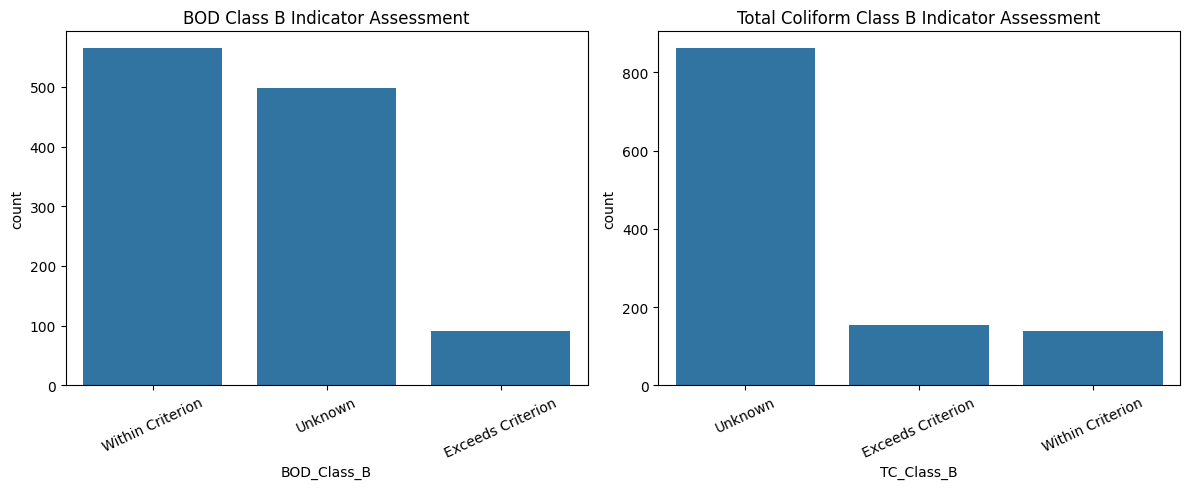

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(data=df, x="BOD_Class_B", ax=axes[0])
axes[0].set_title("BOD Class B Indicator Assessment")
axes[0].tick_params(axis="x", rotation=25)

sns.countplot(data=df, x="TC_Class_B", ax=axes[1])
axes[1].set_title("Total Coliform Class B Indicator Assessment")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

### Pollution Indicator Assessment – Observations

- For BOD, 565 observations (48.9%) were within the CPCB Class B criterion, while 91 observations (7.9%) exceeded it.
- BOD measurements were unavailable for 499 observations (43.2%).
- For Total Coliform, 139 observations (12.0%) were within the criterion, while 154 observations (13.3%) exceeded it.
- Total Coliform measurements were unavailable for 862 observations (74.6%), substantially limiting the assessment.
- The results represent parameter-wise criterion comparisons and do not constitute complete CPCB water-quality classification.

In [36]:
df["BOD_Class_A"] = np.where(
    df["Biochemical_Oxygen_Demand_(mg/L)"].isna(),
    "Unknown",
    np.where(
        df["Biochemical_Oxygen_Demand_(mg/L)"] <= 2,
        "Within Criterion",
        "Exceeds Criterion"
    )
)

df["TC_Class_A"] = np.where(
    df["Total_Coliform_(MPN/100mL)"].isna(),
    "Unknown",
    np.where(
        df["Total_Coliform_(MPN/100mL)"] <= 50,
        "Within Criterion",
        "Exceeds Criterion"
    )
)

df[[
    "Station",
    "Biochemical_Oxygen_Demand_(mg/L)",
    "BOD_Class_A",
    "Total_Coliform_(MPN/100mL)",
    "TC_Class_A"
]].head()

,Station,Biochemical_Oxygen_Demand_(mg/L),BOD_Class_A,Total_Coliform_(MPN/100mL),TC_Class_A
0,ACHANKOVIL AT CHENNITHULA,1.8,Within Criterion,NaN,Unknown
1,ACHANKOVIL AT CHENNITHULA,1.9,Within Criterion,NaN,Unknown
2,ACHANKOVIL AT CHENNITHULA,1.8,Within Criterion,NaN,Unknown
3,ACHANKOVIL AT CHENNITHULA,1.9,Within Criterion,NaN,Unknown
4,ACHANKOVIL AT CHENNITHULA,1.8,Within Criterion,NaN,Unknown


In [37]:
print("BOD Class A Distribution:")
print(df["BOD_Class_A"].value_counts())

print("\nTotal Coliform Class A Distribution:")
print(df["TC_Class_A"].value_counts())

BOD Class A Distribution:
BOD_Class_A
Unknown              499
Within Criterion     386
Exceeds Criterion    270
Name: count, dtype: int64

Total Coliform Class A Distribution:
TC_Class_A
Unknown              862
Exceeds Criterion    278
Within Criterion      15
Name: count, dtype: int64


Task was destroyed but it is pending!
task: <Task pending name='Task-212' coro=<_async_in_context.<locals>.run_in_context() done, defined at C:\Users\sanja\AppData\Local\Programs\Python\Python313\Lib\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-213' coro=<Kernel.shell_main() running at C:\Users\sanja\AppData\Local\Programs\Python\Python313\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Users\sanja\AppData\Local\Programs\Python\Python313\Lib\site-packages\zmq\eventloop\zmqstream.py:564]>
C:\Users\sanja\AppData\Local\Programs\Python\Python313\Lib\site-packages\matplotlib\transforms.py:195: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  ref = weakref.ref(
Task was destroyed but it is pending!
task: <Task pending name='Task-213' coro=<Kernel.shell_main() running at C:\Users\sanja\AppData\Local\Programs\Python\Python313\Lib\site-packages\ipykernel\kernelbase.py:597> 

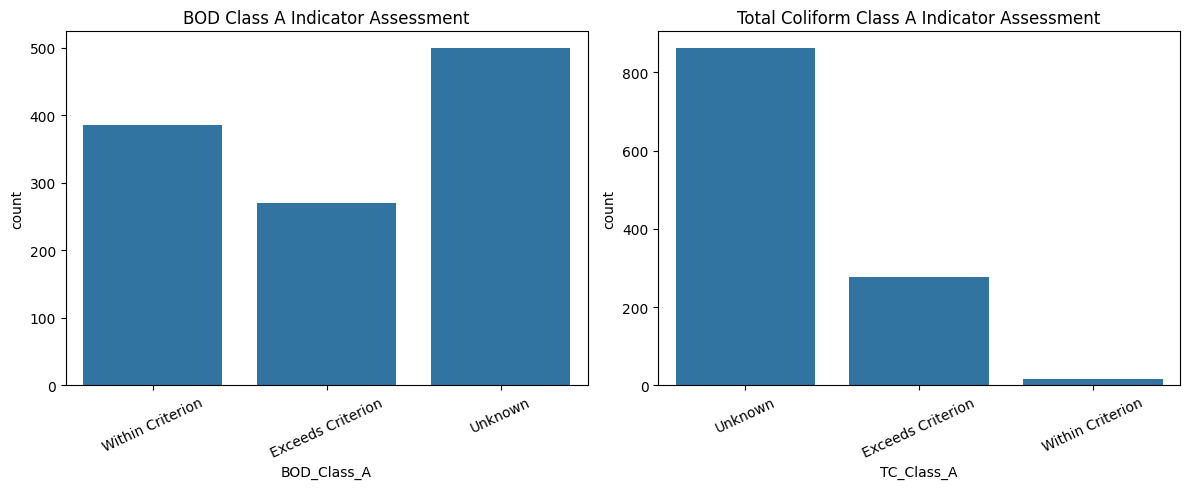

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(data=df, x="BOD_Class_A", ax=axes[0])
axes[0].set_title("BOD Class A Indicator Assessment")
axes[0].tick_params(axis="x", rotation=25)

sns.countplot(data=df, x="TC_Class_A", ax=axes[1])
axes[1].set_title("Total Coliform Class A Indicator Assessment")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

### Drinking-Water Source Suitability Indicators – Observations

- For BOD, 386 observations (33.4%) were within the CPCB Class A criterion of ≤ 2 mg/L, while 270 observations (23.4%) exceeded it.
- BOD measurements were unavailable for 499 observations (43.2%).
- For Total Coliform, only 15 observations (1.3%) were within the Class A criterion of ≤ 50 MPN/100mL, while 278 observations (24.1%) exceeded it.
- Total Coliform measurements were unavailable for 862 observations (74.6%), significantly limiting the assessment.
- Total Coliform showed substantially fewer observations meeting the Class A criterion than BOD.
- These results represent partial indicator comparisons and do not establish drinking-water safety or complete CPCB Class A classification, since DO and pH measurements are unavailable.

In [39]:
bod_comparison = pd.crosstab(
    df["BOD_Class_B"],
    df["BOD_Class_A"]
)

bod_comparison

BOD_Class_A,Exceeds Criterion,Unknown,Within Criterion
BOD_Class_B,,,
Exceeds Criterion,91,0,0
Unknown,0,499,0
Within Criterion,179,0,386


In [40]:
tc_comparison = pd.crosstab(
    df["TC_Class_B"],
    df["TC_Class_A"]
)

tc_comparison

TC_Class_A,Exceeds Criterion,Unknown,Within Criterion
TC_Class_B,,,
Exceeds Criterion,154,0,0
Unknown,0,862,0
Within Criterion,124,0,15


### Comparison of CPCB Class A and Class B Indicators

- Class A criteria are stricter than Class B criteria for both BOD and Total Coliform.
- For BOD, 386 observations met both criteria, 179 met Class B but exceeded Class A, and 91 exceeded both.
- For Total Coliform, 15 observations met both criteria, 124 met Class B but exceeded Class A, and 154 exceeded both.
- The stricter Class A thresholds resulted in fewer observations meeting the criteria, particularly for Total Coliform.
- Missing measurements were consistently classified as Unknown and excluded from criterion exceedance interpretation.
- These comparisons represent parameter-wise assessments and do not establish complete CPCB water-quality classification or drinking-water potability.

In [41]:
station_screen = df.groupby("Station").agg(
    BOD_mean=("Biochemical_Oxygen_Demand_(mg/L)", "mean"),
    BOD_valid=("Biochemical_Oxygen_Demand_(mg/L)", "count"),
    FC_mean=("Fecal_Coliform_(MPN/100mL)", "mean"),
    FC_valid=("Fecal_Coliform_(MPN/100mL)", "count"),
    TC_mean=("Total_Coliform_(MPN/100mL)", "mean"),
    TC_valid=("Total_Coliform_(MPN/100mL)", "count")
)

station_screen.sort_values(
    "BOD_mean", ascending=False
).head(15)

,BOD_mean,BOD_valid,FC_mean,FC_valid,TC_mean,TC_valid
Station,,,,,,
KARAMANA AT MOONNATTUMUKKU KERALA,7.300000,12,4658.333333,12,NaN,0
POND AT (PADMANABHA) SREE PADMANABHA SWAMY TEMPLE (TVPM),6.383333,12,NaN,0,4808.333333,12
ORUVATHILKOTTA LAKE KERALA,6.054545,11,NaN,0,2450.000000,12
KAYAMKULAM KERALA,3.491667,12,NaN,0,1727.500000,12
ASHTHAMUDI LAKE AT QUILON KERALA,3.027273,11,NaN,0,462.500000,12
R KADAMBAYAR AT BRAHMAPURAM,2.983333,12,1324.166667,12,NaN,0
IRUMPANAM KERALA,2.820000,10,2675.000000,12,NaN,0
UNTHITHODU AT ELOOR ERNAKULAM,2.783333,12,NaN,0,8516.666667,12
VELLAYANI LAKE AT VANDITHADOM THIRUVANANTHAPURAM,2.708333,12,NaN,0,964.166667,12


In [42]:
print("Top 10 Stations by Fecal Coliform:")
display(
    station_screen.sort_values(
        "FC_mean", ascending=False
    )[["FC_mean", "FC_valid"]].head(10)
)

print("Top 10 Stations by Total Coliform:")
display(
    station_screen.sort_values(
        "TC_mean", ascending=False
    )[["TC_mean", "TC_valid"]].head(10)
)

Top 10 Stations by Fecal Coliform:


,FC_mean,FC_valid
Station,,
R KALLAI AT KALLAI BRIDGE,17925.000000,12
KARAMANA AT MOONNATTUMUKKU KERALA,4658.333333,12
VALAYAM KERALA,3721.666667,12
IRUMPANAM KERALA,2675.000000,12
PERIYAR AT SEWAGE DISCHARGE POINT KERALA,2371.666667,12
CHALIYAR AT CHUNGAPALLY,2319.166667,12
CHALIYAR AT KOOLIMADU,1929.166667,12
RIVER PERIYAR AT PATHALAM,1895.000000,12
CHALIYAR AT NILAMBUR MALAPPURAM,1873.636364,11


Top 10 Stations by Total Coliform:


,TC_mean,TC_valid
Station,,
VEMBANAD LAKEKOCHI (OIL TANKER JETTY) KERALA,34375.000000,12
PALAKKATTUTHAZHA-MTHODU AT PERUMBAVOOR ERNAKULAM,17900.000000,12
UNTHITHODU AT ELOOR ERNAKULAM,8516.666667,12
POND AT (PADMANABHA) SREE PADMANABHA SWAMY TEMPLE (TVPM),4808.333333,12
ORUVATHILKOTTA LAKE KERALA,2450.000000,12
KANOLI CANAL AT ERANJIKKAL KAZHEKODE,2092.500000,12
WELL AT ALWAYE KERALA,2042.000000,2
KODUNGALLOOR KERALA,1968.333333,12
RSVR AT BHOOTHATHANKETU,1881.166667,12


### Station-wise Bacterial Indicator Screening – Observations

- R Kallai at Kallai Bridge recorded the highest average Fecal Coliform concentration (17,925 MPN/100mL), based on 12 measurements.
- Karamana at Moonattumukku recorded an average Fecal Coliform concentration of 4,658.33 MPN/100mL and the highest average BOD (7.30 mg/L).
- Vembanad Lake Kochi (Oil Tanker Jetty) recorded the highest average Total Coliform concentration (34,375 MPN/100mL), based on 12 measurements.
- Palakkaduthazha–Mthodu at Perumbavoor and Unthithodu at Eloor also recorded comparatively high Total Coliform averages.
- These stations are priority locations for further investigation based on their observed indicator concentrations. Station averages do not imply that every individual sample exceeded a criterion.

In [43]:
df["FC_Class_B"] = np.select(
    [
        df["Fecal_Coliform_(MPN/100mL)"].isna(),
        df["Fecal_Coliform_(MPN/100mL)"] <= 500,
        df["Fecal_Coliform_(MPN/100mL)"] <= 2500
    ],
    [
        "Unknown",
        "Desirable",
        "Permissible"
    ],
    default="Exceeds Maximum"
)

df["FC_Class_B"].value_counts()

FC_Class_B
Desirable          666
Unknown            272
Permissible        154
Exceeds Maximum     63
Name: count, dtype: int64

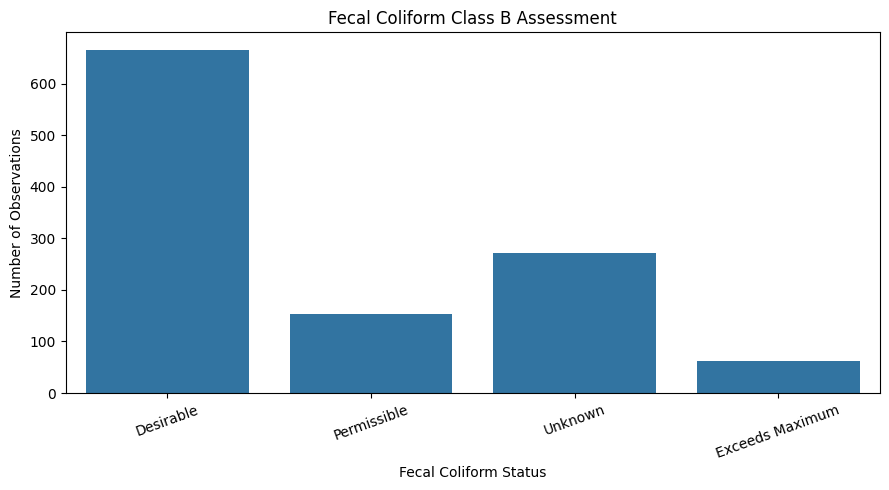

In [44]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="FC_Class_B")

plt.title("Fecal Coliform Class B Assessment")
plt.xlabel("Fecal Coliform Status")
plt.ylabel("Number of Observations")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

### Fecal Coliform Class B Assessment – Observations

- 666 observations (57.7%) were within the desirable Fecal Coliform limit of 500 MPN/100mL.
- 154 observations (13.3%) were between the desirable and maximum permissible limits.
- 63 observations (5.5%) exceeded the maximum permissible limit of 2,500 MPN/100mL.
- Fecal Coliform measurements were unavailable for 272 observations (23.5%).
- These results indicate that some observations exceeded the bathing-water Fecal Coliform maximum permissible criterion, while missing measurements limit the assessment.

In [45]:
fc_station_risk = df.groupby("Station").agg(
    FC_mean=("Fecal_Coliform_(MPN/100mL)", "mean"),
    FC_max=("Fecal_Coliform_(MPN/100mL)", "max"),
    FC_valid=("Fecal_Coliform_(MPN/100mL)", "count"),
    FC_exceed_count=(
        "Fecal_Coliform_(MPN/100mL)",
        lambda x: (x > 2500).sum()
    )
)

fc_station_risk = fc_station_risk[
    fc_station_risk["FC_exceed_count"] > 0
].sort_values("FC_exceed_count", ascending=False)

fc_station_risk.head(15)

,FC_mean,FC_max,FC_valid,FC_exceed_count
Station,,,,
KARAMANA AT MOONNATTUMUKKU KERALA,4658.333333,4900.0,12,12
R KALLAI AT KALLAI BRIDGE,17925.000000,70000.0,12,10
VALAYAM KERALA,3721.666667,17000.0,12,6
IRUMPANAM KERALA,2675.000000,4800.0,12,6
CHALIYAR AT CHUNGAPALLY,2319.166667,7000.0,12,4
PERIYAR NEAR ALWAYE-ELOOR,1669.500000,4000.0,12,3
PERIYAR AT SEWAGE DISCHARGE POINT KERALA,2371.666667,7000.0,12,3
CHALIYAR AT KOOLIMADU,1929.166667,7000.0,12,3
RIVER PERIYAR AT PATHALAM,1895.000000,6300.0,12,3


### Station-wise Fecal Coliform Exceedance Screening – Observations

- Karamana at Moonattumukku recorded exceedances in all 12 available Fecal Coliform measurements, indicating persistent exceedance during the observation period.
- R Kallai at Kallai Bridge recorded 10 exceedances out of 12 measurements, with a maximum concentration of 70,000 MPN/100mL.
- Valayam Kerala and Irumpanam Kerala each recorded six exceedances out of 12 measurements.
- Chaliyar at Chungapally also recorded six exceedances out of 12 measurements.
- Several other Periyar and Chaliyar monitoring stations recorded repeated exceedances.
- These stations are priority locations for further investigation based on Fecal Coliform measurements. Exceedance indicates a bacterial water-quality concern, not a direct determination of drinking-water safety.

# Water Quality Analysis – Final Conclusions

## 1. Overview

This notebook analyzed Kerala water-quality monitoring observations from 2021 to investigate temporal variation, spatial differences, and pollution-related indicators. Monthly, district-wise, and station-wise analyses were performed for Biochemical Oxygen Demand (BOD), Fecal Coliform (FC), and Total Coliform (TC).

## 2. Major Findings

- Water-quality measurements varied across months, districts, and monitoring stations.
- Karamana at Moonattumukku recorded the highest station-average BOD (7.30 mg/L) among the stations examined.
- R Kallai at Kallai Bridge recorded the highest average Fecal Coliform concentration (17,925 MPN/100mL).
- Vembanad Lake Kochi (Oil Tanker Jetty) recorded the highest average Total Coliform concentration (34,375 MPN/100mL).
- Several monitoring stations recorded repeated Fecal Coliform exceedances of the bathing-water maximum permissible criterion.
- Class A indicator comparisons showed that only 15 observations met the Total Coliform criterion of 50 MPN/100mL, while 278 exceeded it.
- Missing measurements, particularly Total Coliform, substantially limited the assessment.

## 3. Assessment Outcomes

Two assessments were conducted:

- **River Pollution Indicator Assessment:** Identified stations and observations with elevated organic pollution and bacterial indicators, using selected CPCB benchmarks for contextual comparison.
- **Class A Water-Quality Indicator Assessmentt:** Compared available BOD and Total Coliform measurements with selected CPCB Class A criteria.

## 4. Limitations

- Missing DO and pH prevent complete CPCB water-quality classification.
- The dataset does not contain a verified drinking-water potability label.
- Indicator comparisons do not establish drinking-water safety.
- Missing measurements reduce the reliability and completeness of station comparisons.
- BOD measurement-method compatibility with CPCB criteria has not been independently confirmed.

## 5. Conclusion

The analysis identified spatial and temporal variations in water-quality indicators and highlighted monitoring stations requiring further investigation. Bacterial indicator exceedances were observed at several locations, while substantial missingness limited some assessments.

The results provide an exploratory foundation for further water-quality monitoring and analytical modeling. They should not be interpreted as official CPCB classifications or drinking-water safety certifications.